## Qualitative Analysis

1. Label validity: Does the original gold label (RQ/IQ) still hold with the swapped context?
2. Coherence: Does the swapped context form a make sense with the target question?
3. Prediction sensitivity: Do Logistic Regression and RoBERTa change their predictions? Does that correspond to a plausible change in interpretation?

In [17]:
# imports

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [12]:
# loading processed data and saved predictions

test = pd.read_json("../data/test_processed.jsonl", lines=True)

lr = pd.read_csv("lr_predictions.csv")
roberta = pd.read_csv("roberta_predictions.csv")

In [13]:
# combining both model predictions into one dataframe

df = lr.merge(
    roberta,
    on="id",
    suffixes=("_lr", "_roberta"),
    validate="one_to_one"
)

# sanity checking size, question-matching, and order
assert len(df) == len(test) == 438
assert (df["question_lr"] == df["question_roberta"]).all()
assert (df["question_lr"].to_numpy() == test["question"].to_numpy()).all()

# adding the contexts
df["original_context"] = test["preceding_turns"].to_numpy()
df["swapped_context"] = test["swapped_context"].to_numpy()

# identifying changed predictions for both models
df["lr_changed"] = df["lr_real"] != df["lr_swapped"]
df["roberta_changed"] = df["roberta_real"] != df["roberta_swapped"]

In [14]:
# choosing samples from specific categories of prediction changes between real and swapped context

label_map = {0: "informational", 1: "rhetorical"}

df["roberta_real_label"] = df["roberta_real"].map(label_map)
df["roberta_swapped_label"] = df["roberta_swapped"].map(label_map)

# defining the five groups
both = df["lr_changed"] & df["roberta_changed"]
same_direction = df["lr_real"] == df["roberta_real_label"]

groups = {
    "both_same": df[both & same_direction],
    "both_opposite": df[both & ~same_direction],
    "lr_only": df[df["lr_changed"] & ~df["roberta_changed"]],
    "roberta_only": df[~df["lr_changed"] & df["roberta_changed"]],
    "neither": df[~df["lr_changed"] & ~df["roberta_changed"]]
}

# getting samples with random seed 42 (2 for each group)
samples = []

for name, group in groups.items():
    selected = group.sample(n=2, random_state=42).copy()
    selected["category"] = name
    samples.append(selected)

qualitative_sample = pd.concat(samples, ignore_index=True)

In [15]:
# exporting annotation sheet for manual analysis

columns = [
    "id", "category", "question_lr", "gold_lr",
    "original_context", "swapped_context",
    "lr_real", "lr_swapped",
    "roberta_real_label", "roberta_swapped_label"
]

qualitative_sample[columns].to_csv(
    "qualitative_analysis.csv",
    index=False
)

Results: 
 
...

### Are RQs or IQs more affected by context swapping?

In [ ]:
# calculating prediction-change rates by original gold label

results = df.groupby("gold_lr").agg(
    n=("id", "count"),
    lr_changes=("lr_changed", "sum"),
    lr_change_rate=("lr_changed", "mean"),
    roberta_changes=("roberta_changed", "sum"),
    roberta_change_rate=("roberta_changed", "mean")
)

results["lr_change_rate"] *= 100
results["roberta_change_rate"] *= 100

print(results.round(1))


                 n  lr_changes  lr_change_rate  roberta_changes  \
gold_lr                                                           
informational  140          52            37.1               44   
rhetorical     298          86            28.9              103   

               roberta_change_rate  
gold_lr                             
informational                 31.4  
rhetorical                    34.6  


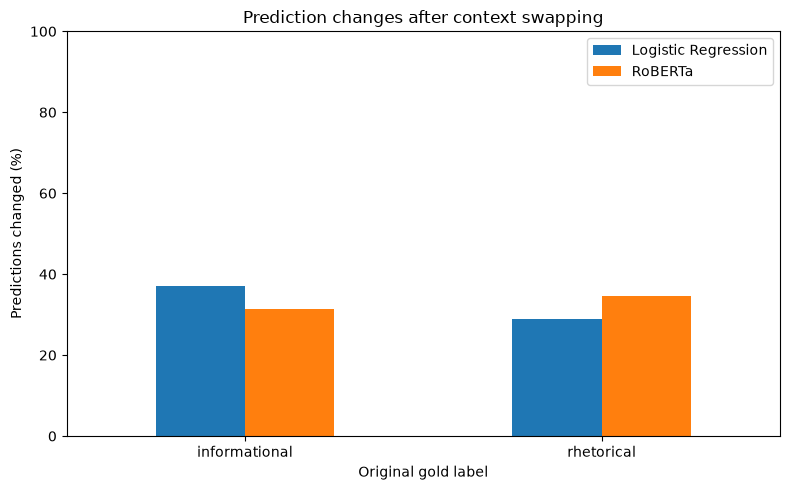

In [18]:
# visualizing results

results[["lr_change_rate", "roberta_change_rate"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Prediction changes after context swapping")
plt.xlabel("Original gold label")
plt.ylabel("Predictions changed (%)")
plt.xticks(rotation=0)
plt.legend(["Logistic Regression", "RoBERTa"])
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


Grouped by original gold labels:

- RoBERTa: 31.4% of IQ predictions change to RQ, 34.6% of RQ predictions change to IQ
- Logistic Regression: 37.1% of IQ predictions change to RQ, 28.9% of RQ predictions change to IQ

In [19]:
# calculating prediction-change rates by original predicted class

for model in ["lr", "roberta"]:
    results_pred = df.groupby(f"{model}_real").agg(
        n=("id", "count"),
        changes=(f"{model}_changed", "sum"),
        change_rate=(f"{model}_changed", "mean")
    )

    results_pred["change_rate"] *= 100

    print(f"\n{model.upper()} — by original predicted class")
    print(results_pred.round(1))



LR — by original predicted class
                 n  changes  change_rate
lr_real                                 
informational  134       66         49.3
rhetorical     304       72         23.7

ROBERTA — by original predicted class
                n  changes  change_rate
roberta_real                           
0             118       72         61.0
1             320       75         23.4


Grouped by original predictions:

- RoBERTa: 61.0% of IQ predictions change to RQ, 23.4% of RQ predictions change to IQ
- Logistic Regression: 49.3% of IQ predictions change to RQ, 23.7% of RQ predictions change to IQ


Results:  

- different context sensitivity depending on whether goruped by original gold labels or model predictions
- relatively small differences between gold-label groups + inconsistent across the two models
- less stable IQ predictions for both models (substantially)

### Why does RoBERTa predict almost only IQs in the no context condition?

...

### Are short or particular question forms more sensitive?

...